# Rain and wildfire power: results

Reproduces every figure and table in the [README](../README.md) from `data/final/` (built by the pipeline; see the README's
*Reproducing* section). The numbered sections follow the order of analysis:
outcome-blind checks first, then the locked models, then the checks added after results were seen.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path().resolve()))
import checks, models, robustness

pd.set_option("display.float_format", "{:.3f}".format)
t = pd.read_parquet("../data/final/analysis.parquet")
v = t[(t.cc_thr == 0.3) & t.valid]
print(f"{t.window_id.nunique():,} fire-days after filters; {len(v):,} pass cloud screening at 30% "
      f"({v.fire_id.nunique():,} fires, {v.year.min()}-{v.year.max()})")
pd.crosstab(v.pardig_bin, v.fuel, margins=True)

16,033 fire-days after filters; 9,279 pass cloud screening at 30% (1,913 fires, 2019-2025)


fuel,forest,non-forest,All
pardig_bin,,,
<0.1,6565,1797,8362
0.1-2,502,140,642
2-5,130,29,159
5+,84,32,116
All,7281,1998,9279


## 1. Outcome-blind checks

**Figure 2.** On dry days, the share of overpasses that miss a fire that was detected on clear looks the day before
and after, by ERA5 cloud cover. It motivates cloud screening and supports the 30% cutoff.

Cloud validation: share of looks with no detection, by cloud cover
            size  mean    lo    hi
bin                               
[0.0, 0.1)  5257 0.046 0.039 0.054
[0.1, 0.2)   353 0.085 0.056 0.119
[0.2, 0.3)   189 0.085 0.043 0.132
[0.3, 0.4)   194 0.062 0.031 0.096
[0.4, 0.5)   123 0.081 0.037 0.137
[0.5, 0.6)   138 0.080 0.037 0.136
[0.6, 0.7)   116 0.190 0.116 0.273
[0.7, 0.8)    98 0.153 0.080 0.237
[0.8, 0.9)   101 0.208 0.129 0.295
[0.9, 1.0)   145 0.462 0.362 0.556


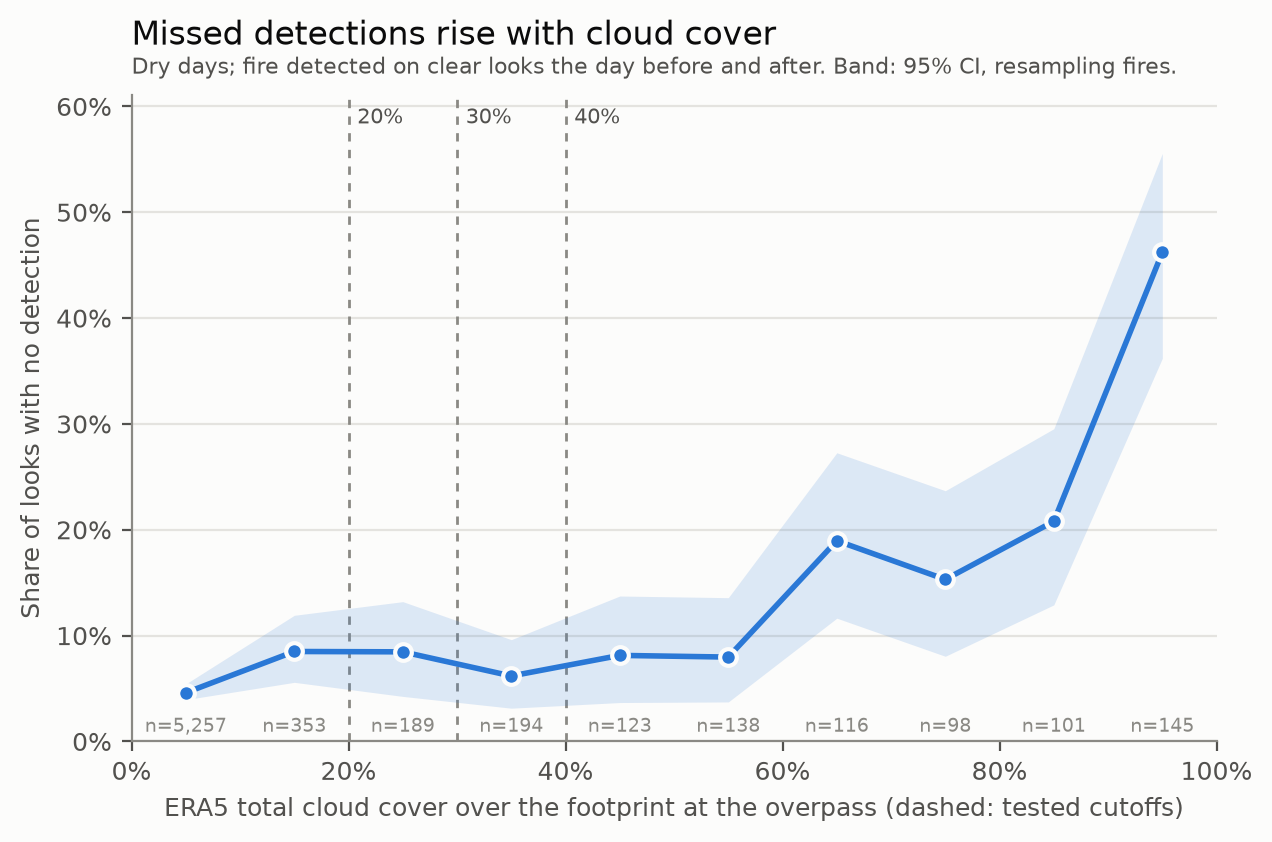

In [2]:
checks.OUT.mkdir(parents=True, exist_ok=True)
checks.cloud_validation()
display(Image(checks.OUT / "fig2_cloud_validation.png", width=700))

**Table 1.** The share of fire-days kept by cloud screening in each rain bin, and how kept windows differ from
dropped ones. This defines what the claim covers.

In [3]:
checks.dropout()
pd.read_csv(checks.OUT / "table1_dropout.csv", index_col=0).T


Dropout table (30% unless noted; medians for rain and duration, shares and mean post cloud otherwise)
PARDIG W rain               <0.1    0.1-2     2-5      5+
windows                12513.000 2030.000 802.000 688.000
kept at 20%                0.590    0.220   0.140   0.100
kept at 30%                0.670    0.320   0.200   0.170
kept at 40%                0.740    0.410   0.280   0.260
rain mm, kept              0.000    0.600   3.030   7.860
duration h, kept           0.000    0.840   2.690   4.230
Oct-Nov share, kept        0.250    0.110   0.150   0.070
forest share, kept         0.790    0.780   0.820   0.720
post cloud, kept           0.180    0.270   0.320   0.320
rain mm, dropped           0.000    0.660   3.170   8.670
duration h, dropped        0.000    0.910   3.100   5.770
Oct-Nov share, dropped     0.280    0.210   0.210   0.170
forest share, dropped      0.810    0.840   0.800   0.830
post cloud, dropped        0.590    0.650   0.670   0.700


PARDIG W rain,<0.1,0.1-2,2-5,5+
windows,12513.000,2030.000,802.000,688.000
kept at 20%,0.589,0.222,0.136,0.097
kept at 30%,0.668,0.316,0.198,0.169
kept at 40%,0.739,0.414,0.283,0.260
"rain mm, kept",0.000,0.601,3.031,7.856
"duration h, kept",0.000,0.838,2.689,4.229
"Oct-Nov share, kept",0.254,0.112,0.151,0.069
"forest share, kept",0.785,0.782,0.818,0.724
"post cloud, kept",0.181,0.273,0.317,0.323
"rain mm, dropped",0.000,0.663,3.168,8.669


## 2. Locked models

**Figure 1** (dose-response by fuel at three cloud cutoffs) and **Table 2** (PARDIG vs IMERG: how much each product's
rain improves prediction of fire response on held-out fires, 5-fold cross-validation grouped by fire).

Dose-response: % change in FRP vs < 0.1 mm  [95% CI]  (n windows)

  cutoff 20%
    forest     0.1-2 mm:  -42.3%  [ -51.9,  -30.7]  (n=361, 265 fires)
    forest       2-5 mm:  -67.7%  [ -76.3,  -56.0]  (n=91, 84 fires)
    forest        5+ mm:  -85.1%  [ -90.0,  -77.7]  (n=50, 48 fires)
    non-forest 0.1-2 mm:  -23.0%  [ -47.7,  +13.5]  (n=90, 77 fires)
    non-forest   2-5 mm:  -62.1%  [ -81.7,  -21.8]  (n=18, 18 fires)
    non-forest    5+ mm:  -74.1%  [ -88.2,  -43.1]  (n=17, 17 fires)

  cutoff 30%
    forest     0.1-2 mm:  -42.2%  [ -50.0,  -33.2]  (n=502, 351 fires)
    forest       2-5 mm:  -66.2%  [ -73.7,  -56.6]  (n=130, 117 fires)
    forest        5+ mm:  -85.3%  [ -89.3,  -79.6]  (n=84, 75 fires)
    non-forest 0.1-2 mm:  -22.1%  [ -44.1,   +8.6]  (n=140, 112 fires)
    non-forest   2-5 mm:  -69.7%  [ -81.6,  -50.1]  (n=29, 29 fires)
    non-forest    5+ mm:  -73.6%  [ -84.6,  -54.5]  (n=32, 29 fires)

  cutoff 40%
    forest     0.1-2 mm:  -42.6%  [ -49.3,  -34.9]  (n=6

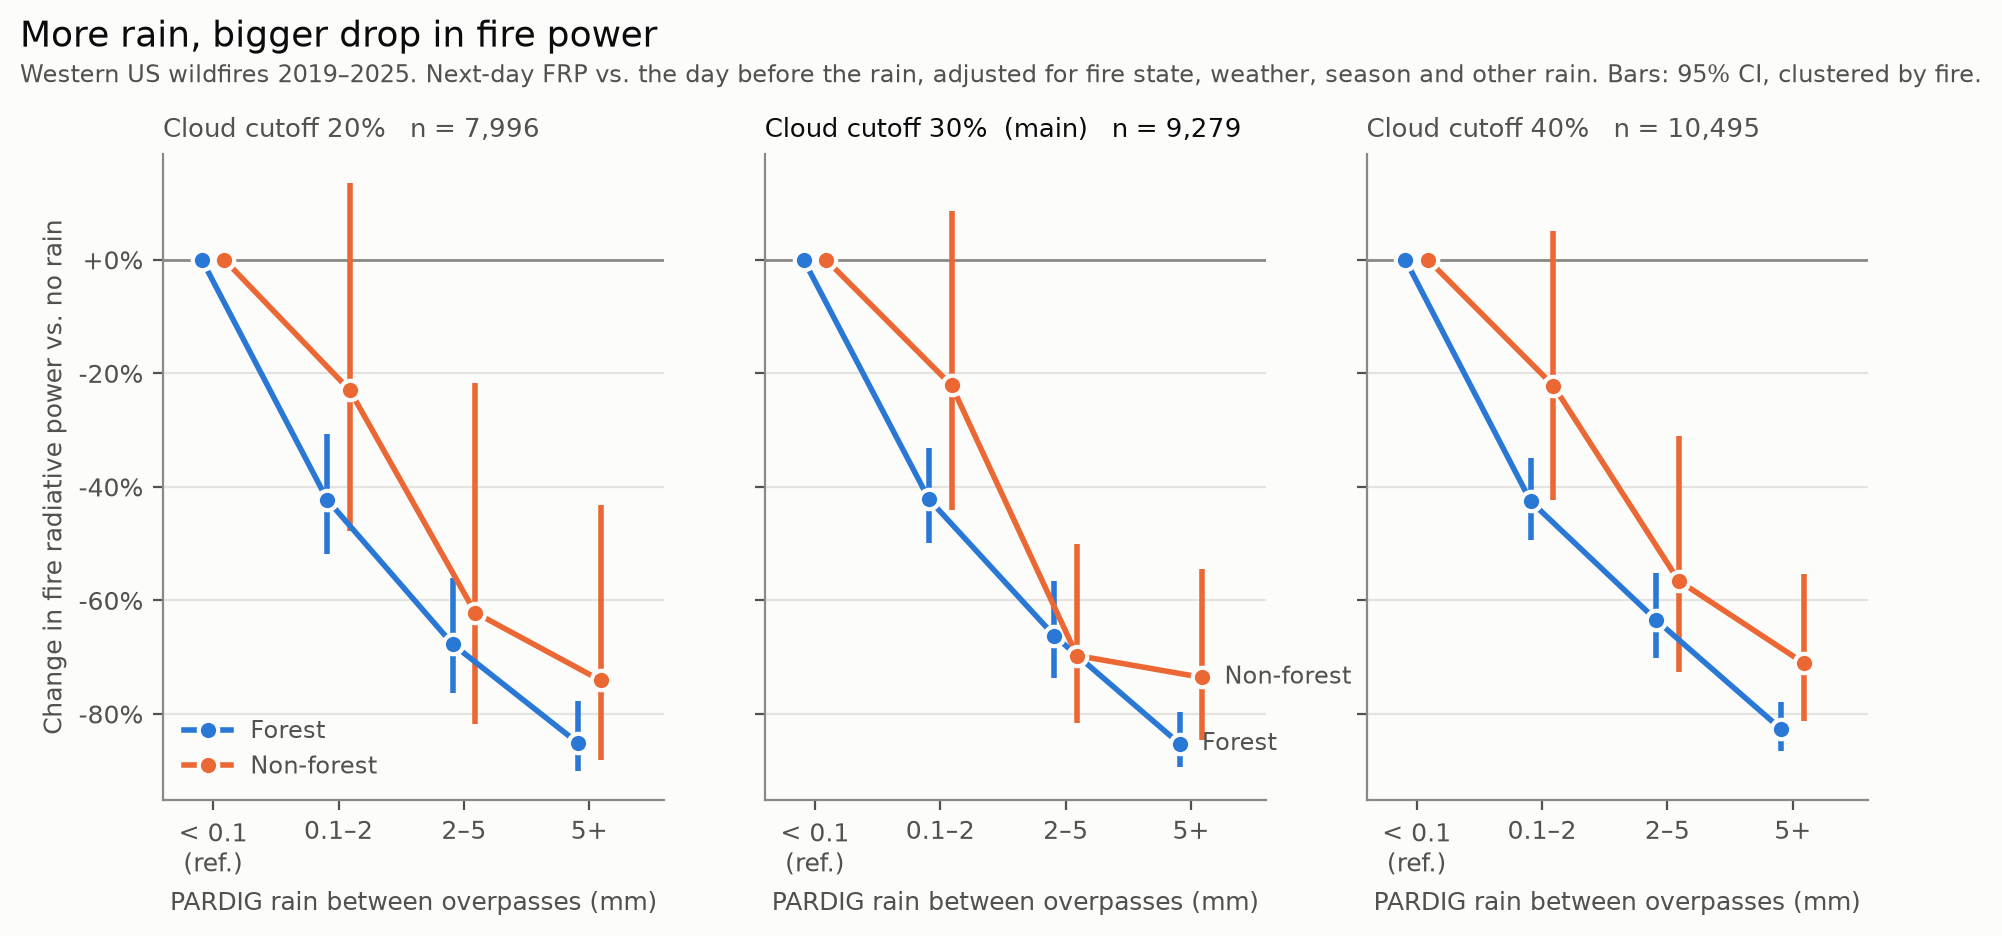

In [4]:
models.main()
display(Image(models.OUT / "fig1_dose_response.png", width=950))

In [5]:
ho = pd.read_csv(models.OUT / "table2_heldout.csv")
ho[["thr", "n", "r2_no_rain", "r2_pardig", "r2_imerg", "gain_pardig", "gain_imerg", "gain_ratio",
    "pardig_better_share", "pardig_better_share_rainy"]]

,thr,n,r2_no_rain,r2_pardig,r2_imerg,gain_pardig,gain_imerg,gain_ratio,pardig_better_share,pardig_better_share_rainy
0,0.200,7996,0.182,0.206,0.200,0.024,0.018,1.347,0.983,0.995
1,0.300,9279,0.183,0.221,0.211,0.038,0.028,1.377,1.000,1.000
2,0.400,10495,0.186,0.230,0.220,0.044,0.034,1.274,1.000,1.000


Supporting detail: both products in one regression. The two rain series are correlated (r = 0.78), so the
individual coefficients are imprecise; the held-out comparison above is the main result.

In [6]:
jm = pd.read_csv(models.OUT / "joint_model.csv")
jm.pivot_table(index=["thr", "model"], columns="product", values="coef", sort=False)

product             PARDIG  IMERG
thr   model                      
0.200 PARDIG alone  -0.764    NaN
      IMERG alone      NaN -0.663
      both          -0.617 -0.191
0.300 PARDIG alone  -0.759    NaN
      IMERG alone      NaN -0.677
      both          -0.626 -0.179
0.400 PARDIG alone  -0.688    NaN
      IMERG alone      NaN -0.646
      both          -0.549 -0.192

## 3. Checks added after the results were seen

Placebo (rain after the measurement), cloud-cover control, the bounding model (post-storm temperature and humidity
held fixed), PARDIG coarsened to 30-minute slots, and the held-out comparison under the cloud control.

In [7]:
robustness.main()


main (reference)
    forest 0.1-2 mm             -42.2%  [ -50.0,  -33.2]  p=1e-13
    forest 2-5 mm               -66.2%  [ -73.7,  -56.6]  p=2.8e-17
    forest 5+ mm                -85.3%  [ -89.3,  -79.6]  p=3.5e-31
    non-forest 0.1-2 mm         -22.1%  [ -44.1,   +8.6]  p=0.14
    non-forest 2-5 mm           -69.7%  [ -81.6,  -50.1]  p=2.7e-06
    non-forest 5+ mm            -73.6%  [ -84.6,  -54.5]  p=1.5e-06

placebo: W effects with lead-rain bins added
    forest 0.1-2 mm             -42.3%  [ -50.1,  -33.3]  p=9.4e-14
    forest 2-5 mm               -66.3%  [ -73.8,  -56.7]  p=2.3e-17
    forest 5+ mm                -85.3%  [ -89.4,  -79.7]  p=4.3e-31
    non-forest 0.1-2 mm         -21.9%  [ -44.0,   +8.7]  p=0.14
    non-forest 2-5 mm           -69.5%  [ -81.5,  -49.9]  p=2.9e-06
    non-forest 5+ mm            -73.5%  [ -84.6,  -54.1]  p=2e-06

placebo: lead-rain bins (should be ~0)
    lead 0.1-2 mm (n=1001)       +4.3%  [  -5.8,  +15.4]  p=0.42
    lead 2-5 mm (n=351)  